# PINN for the heat equation (PDE) — forward & inverse

The course's PDE benchmark from lecture 1, now solved **mesh-free** with a PINN.

$$\frac{\partial u}{\partial t} = \alpha\,\frac{\partial^2 u}{\partial x^2},\quad x\in[0,1],\; u(0,t)=u(1,t)=0,\; u(x,0)=\sin(\pi x).$$

This problem has the **exact** solution $u(x,t)=e^{-\alpha\pi^2 t}\sin(\pi x)$, so we can score the PINN against ground truth.
The derivative calls used below are explained step by step in `pinn_autodiff`.

**The canonical rod.** This is the *first member* of the course's canonical heat-rod
family (`pyutils/benchmarks/heat1d.py`: $\alpha=0.1$, $x\in[0,1]$, Dirichlet walls,
initial profiles $a(x)=\sum_{k=1}^{8}c_k\sin(k\pi x)$, with $c=e_1$ giving $\sin\pi x$)
that Modules 02, 20, 21, 25 and 26 all use. The operator modules run the *whole family*
to $t_f=0.05$; the PINN here runs this *one member* to $t=1$. The reference solution and
the family used in the last section come from that shared module, not from a local formula.

The prose describes the **default** run. Change the values below and *Run All*;
every figure and printout follows. Checks that quote slide numbers are skipped
when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0
ALPHA_TRUE = 0.1          # diffusivity
T_END = 1.0               # time horizon
HIDDEN = [32, 32, 32]     # hidden layer widths
N_COL, N_IC, N_BC = 2000, 200, 200   # collocation / initial / boundary points per step
W_IC, W_BC = 10.0, 10.0   # loss weights on the IC and BC terms
STEPS, LR = 4000, 2e-3    # Adam
LBFGS_ITERS = 300         # L-BFGS refinement iterations (0 = skip)
N_DATA, NOISE = 60, 0.01  # inverse problem: interior measurements and their noise std
ALPHA_INIT = 0.5          # inverse problem: initial guess for alpha
W_DATA = 100.0            # inverse problem: data weight
STEPS_INV = 4000
RUN_SEED_SWEEP = False    # True: rerun everything for SWEEP_SEEDS (~6 min) and save the table
SWEEP_SEEDS = [0, 1, 2, 3, 4]
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, ALPHA_TRUE=0.1, T_END=1.0, HIDDEN=[32, 32, 32],
                N_COL=2000, N_IC=200, N_BC=200, W_IC=10.0, W_BC=10.0,
                STEPS=4000, LR=2e-3, LBFGS_ITERS=300, N_DATA=60, NOISE=0.01,
                ALPHA_INIT=0.5, W_DATA=100.0, STEPS_INV=4000)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

In [2]:
import sys, os, time, copy, json
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP, grad, train
from pyutils import save_dual, fg
from pyutils.benchmarks import heat1d   # the canonical rod shared by Modules 02, 20, 21, 25, 26
torch.set_default_dtype(torch.float64)   # 2nd-order residuals need float64
pc.set_plot_style()
FIG = os.path.abspath(os.path.join('..','figures')); os.makedirs(FIG, exist_ok=True)
SWEEP_FILE = os.path.abspath(os.path.join('..','data','pinn_heat_pde_seed_sweep.json'))

if AT_DEFAULTS:
    assert ALPHA_TRUE == heat1d.ALPHA, "the PINN benchmark is the canonical rod (alpha = 0.1)"
C_FIRST = np.array([1.0])   # c = e_1: the first member of the sine family, a(x) = sin(pi x)

def exact(x, t):
    """Reference u(x, t) of the canonical rod for the first family member (alpha follows the parameter cell)."""
    return heat1d.exact(C_FIRST, x, t, alpha=ALPHA_TRUE)

# independent validation grid (never used for training)
xg, tg = np.meshgrid(np.linspace(0, 1, 101), np.linspace(0, T_END, 101))
XX = torch.tensor(np.c_[xg.ravel(), tg.ravel()])
u_ref = exact(xg, tg)

def errors(model):
    """Relative L2 and max-abs error of a network on the validation grid."""
    with torch.no_grad(): up = model(XX).numpy().reshape(xg.shape)
    return np.linalg.norm(up - u_ref)/np.linalg.norm(u_ref), np.abs(up - u_ref).max(), up

## Forward problem

Network $\hat u_\theta(x,t)$; loss = residual + IC + BC (no data).
The second derivative $u_{xx}$ is built by differentiating the network twice with autograd.
Collocation points are redrawn every step.

The forward experiment is one function of the seed (initialization and
collocation draws), so the default run and the optional seed sweep share code.
It also runs the L-BFGS test described in the next section.

In [3]:
def sample(n):
    x = torch.rand(n,1); t = torch.rand(n,1)*T_END
    return x.requires_grad_(True), t.requires_grad_(True)

def loss_terms(model, x, t, xi, tb):
    # physics residual at collocation points
    u = model(torch.cat([x,t],1))
    u_t = grad(u, t); u_x = grad(u, x); u_xx = grad(u_x, x)
    Lr = ((u_t - ALPHA_TRUE*u_xx)**2).mean()
    # initial condition u(x,0)=sin(pi x)
    u0 = model(torch.cat([xi, torch.zeros_like(xi)],1))
    Li = ((u0 - torch.sin(np.pi*xi))**2).mean()
    # boundary u(0,t)=u(1,t)=0
    ub = model(torch.cat([torch.zeros_like(tb),tb],1))
    ub2 = model(torch.cat([torch.ones_like(tb),tb],1))
    Lb = (ub**2).mean() + (ub2**2).mean()
    return Lr, Li, Lb

def resampled_loss(model):
    x, t = sample(N_COL)
    Lr, Li, Lb = loss_terms(model, x, t, torch.rand(N_IC,1), torch.rand(N_BC,1)*T_END)
    return Lr + W_IC*Li + W_BC*Lb

def run_forward(seed, log_every=0):
    torch.manual_seed(seed)
    out = {}
    net = MLP([2, *HIDDEN, 1])
    # Adam with step decay (as pinn_core.train), written out so that the optimizer
    # state can be continued in the fair comparison below
    opt_a = torch.optim.Adam(net.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.StepLR(opt_a, step_size=2000, gamma=0.5)
    def adam_step(model):
        opt_a.zero_grad(); L = resampled_loss(model); L.backward(); opt_a.step(); sched.step()
        return L.item()
    t0 = time.perf_counter(); hist = []
    for k in range(STEPS):
        hist.append(adam_step(net))
        if log_every and k % log_every == 0:
            print(f"step {k:6d}   loss {hist[-1]:.3e}")
    out['hist'] = hist
    out['t_adam'] = time.perf_counter() - t0
    out['rel_adam'], out['max_adam'], out['up_adam'] = errors(net)

    # --- L-BFGS refinement on a fixed collocation set ---
    x_fix, t_fix = sample(N_COL)
    xi_fix, tb_fix = torch.rand(N_IC,1), torch.rand(N_BC,1)*T_END
    def fixed_loss(model):
        Lr, Li, Lb = loss_terms(model, x_fix, t_fix, xi_fix, tb_fix)
        return Lr + W_IC*Li + W_BC*Lb
    net_lb = copy.deepcopy(net); hist_lb = []
    t0 = time.perf_counter()
    if LBFGS_ITERS > 0:
        opt = torch.optim.LBFGS(net_lb.parameters(), lr=1.0, max_iter=LBFGS_ITERS,
                                history_size=50, line_search_fn='strong_wolfe',
                                tolerance_grad=1e-12, tolerance_change=1e-15)
        def closure():
            opt.zero_grad(); L = fixed_loss(net_lb); L.backward()
            hist_lb.append(L.item()); return L
        opt.step(closure)
    out['t_lb'] = time.perf_counter() - t0
    out['hist_lb'] = hist_lb
    out['rel_lb'], out['max_lb'], _ = errors(net_lb)

    # --- the same number of loss/gradient evaluations spent on continuing Adam ---
    # (same optimizer state and schedule; net itself is trained further, net_lb was copied)
    hist_more = []; t0 = time.perf_counter()
    for _ in range(len(hist_lb)):
        hist_more.append(adam_step(net))
    net_more = net
    out['t_more'] = time.perf_counter() - t0
    out['hist_more'] = hist_more
    out['rel_more'], out['max_more'], _ = errors(net_more)
    return out

fwd = run_forward(SEED, log_every=1000)
hist, t_adam, rel_adam, max_adam, up_adam = (fwd[k] for k in ['hist', 't_adam', 'rel_adam', 'max_adam', 'up_adam'])
print(f'final loss {hist[-1]:.2e} after {STEPS} Adam steps ({t_adam:.0f} s)')
print(f'relative L2 error {rel_adam:.2e}   max abs error {max_adam:.2e}')

step      0   loss 1.106e+01


step   1000   loss 6.064e-03


step   2000   loss 1.759e-03


step   3000   loss 8.258e-04


final loss 5.50e-04 after 4000 Adam steps (37 s)
relative L2 error 4.73e-03   max abs error 6.82e-03


### Forward result vs exact solution

The error is measured on a $101\times101$ grid that the network never trained
on. A small *loss* is not the same thing as a small *error*; the exact
solution lets us check the second directly.

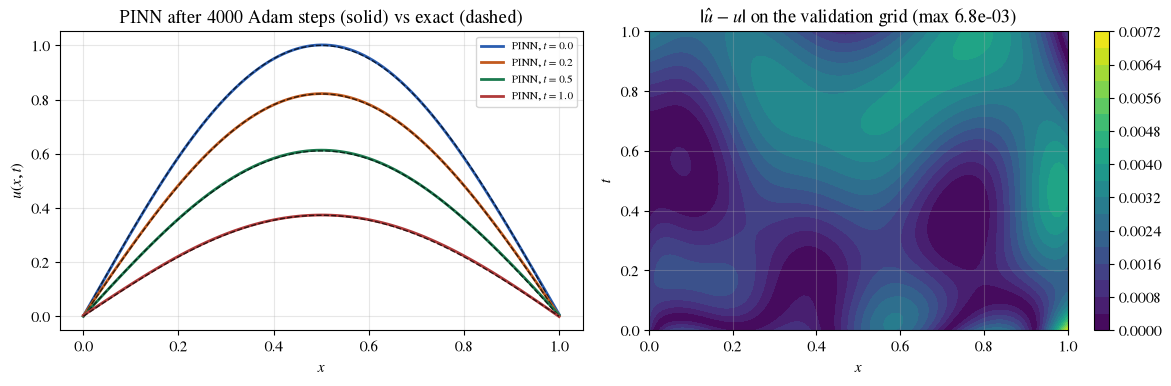

In [4]:
def plot_heat_forward(up=up_adam, title_err=max_adam):
    fig, ax = plt.subplots(1,2, figsize=(12,4))
    xs = xg[0]
    for k, tt in enumerate([0.0, 0.2, 0.5, 1.0]):
        j = np.argmin(np.abs(tg[:,0]-tt*T_END))
        ax[0].plot(xs, up[j], color=f'C{k}', lw=2, label=f'PINN, $t={tg[j,0]:.1f}$')
        ax[0].plot(xs, u_ref[j], '--', color=fg(), lw=1, alpha=0.7)
    ax[0].set(title=f'PINN after {STEPS} Adam steps (solid) vs exact (dashed)', xlabel='$x$', ylabel='$u(x,t)$')
    ax[0].legend(fontsize=8)
    c = ax[1].contourf(xg, tg, np.abs(up-u_ref), 20); fig.colorbar(c, ax=ax[1])
    ax[1].set(title=f'$|\\hat u - u|$ on the validation grid (max {title_err:.1e})', xlabel='$x$', ylabel='$t$')
    plt.tight_layout()

save_dual(plot_heat_forward, 'pinn_heat_forward', FIG)
plt.show()

### Does L-BFGS refinement help? A controlled test

The slides recommend "Adam, then L-BFGS". We test it rather than assume it.
Starting from the same Adam solution, compare

* **L-BFGS** on a *fixed* set of collocation points (a deterministic loss, which
  its line search needs), against
* **continuing Adam** (same optimizer state and learning-rate schedule) for
  as many steps as L-BFGS used loss-and-gradient evaluations — an equal,
  machine-independent budget, since each costs one forward and one backward
  pass. L-BFGS's count includes its line-search trial evaluations.

Wall-clock times are printed too, but they depend on the machine.

Both are scored on the independent validation grid. (The runs happened inside
`run_forward` above; this cell reports them.)

In [5]:
hist_lb, t_lb, rel_lb, max_lb = (fwd[k] for k in ['hist_lb', 't_lb', 'rel_lb', 'max_lb'])
hist_more, t_more, rel_more, max_more = (fwd[k] for k in ['hist_more', 't_more', 'rel_more', 'max_more'])
print(f'                       rel L2     max abs    time')
print(f'Adam {STEPS} steps        {rel_adam:.2e}   {max_adam:.2e}   {t_adam:5.1f} s')
print(f'  + L-BFGS ({len(hist_lb)} evals)  {rel_lb:.2e}   {max_lb:.2e}   +{t_lb:4.1f} s')
print(f'  + Adam ({len(hist_more)} steps)   {rel_more:.2e}   {max_more:.2e}   +{t_more:4.1f} s')

                       rel L2     max abs    time
Adam 4000 steps        4.73e-03   6.82e-03    37.1 s
  + L-BFGS (329 evals)  3.15e-04   5.60e-04   + 3.4 s
  + Adam (329 steps)   2.43e-03   4.76e-03   + 3.0 s


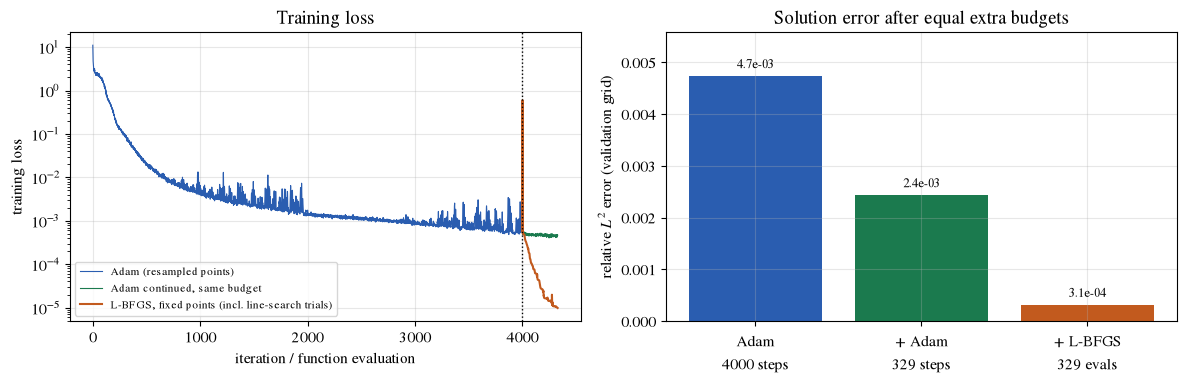

In [6]:
def plot_heat_lbfgs():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].semilogy(hist, color='C0', lw=0.8, label='Adam (resampled points)')
    n0 = len(hist)
    ax[0].semilogy(range(n0, n0+len(hist_more)), hist_more, color='C2', lw=0.8, label='Adam continued, same budget')
    ax[0].semilogy(range(n0, n0+len(hist_lb)), hist_lb, color='C1', lw=1.5, label='L-BFGS, fixed points (incl. line-search trials)')
    ax[0].axvline(n0, color=fg(), ls=':', lw=1)
    ax[0].set(xlabel='iteration / function evaluation', ylabel='training loss',
              title='Training loss')
    ax[0].legend(fontsize=8)
    labels = [f'Adam\n{STEPS} steps', f'+ Adam\n{len(hist_more)} steps', f'+ L-BFGS\n{len(hist_lb)} evals']
    vals = [rel_adam, rel_more, rel_lb]
    ax[1].bar(labels, vals, color=['C0', 'C2', 'C1'])
    ax[1].set_ylim(0, 1.18*max(vals))
    ax[1].set(ylabel='relative $L^2$ error (validation grid)',
              title='Solution error after equal extra budgets')
    for i, v in enumerate(vals):
        ax[1].text(i, v + 0.02*max(vals), f'{v:.1e}', ha='center', va='bottom', color=fg(), fontsize=9)
    plt.tight_layout()

save_dual(plot_heat_lbfgs, 'pinn_heat_lbfgs', FIG)
plt.show()

In [7]:
assert np.isfinite(hist).all() and hist[-1] < 1e-2, "Adam training converged to a small loss"
assert rel_adam < 2e-2, f"forward PINN relative L2 error {rel_adam:.2e}"
if LBFGS_ITERS > 0:
    assert np.isfinite(hist_lb).all() and rel_lb < rel_adam, "L-BFGS refinement reduces the solution error"

## Inverse problem — recover the diffusivity $\alpha$

Now $\alpha$ is **unknown**. Given a few noisy measurements, train the network
and $\alpha$ jointly: physics residual (with trainable $\alpha$) + data term.

**What is and is not given.** This experiment uses *only* interior
measurements and the PDE: no initial or boundary condition enters the loss.
It is a reconstruction of the field and of $\alpha$ from scattered data — the
setting of a sensor network that does not observe the boundaries. If the IC
and BCs were known, adding them would constrain the problem further.

In [8]:
def run_inverse(seed, log_every=0):
    torch.manual_seed(seed + 1)
    rng = np.random.default_rng(seed)        # all NumPy randomness goes through this generator
    net2 = MLP([2, *HIDDEN, 1])
    log_alpha = torch.tensor(np.log(ALPHA_INIT), requires_grad=True)
    # sparse noisy 'measurements' from the exact solution
    xd = rng.random(N_DATA); td = rng.random(N_DATA)*T_END
    ud = exact(xd, td) + NOISE*rng.standard_normal(N_DATA)
    Xd = torch.tensor(np.c_[xd, td]); Ud = torch.tensor(ud).reshape(-1,1)
    def loss_inv():
        a = torch.exp(log_alpha)
        x,t = sample(N_COL)
        u = net2(torch.cat([x,t],1))
        u_t = grad(u,t); u_xx = grad(grad(u,x), x)
        Lr = ((u_t - a*u_xx)**2).mean()
        Ld = ((net2(Xd) - Ud)**2).mean()
        return Lr + W_DATA*Ld
    hist2 = train(loss_inv, list(net2.parameters())+[log_alpha], steps=STEPS_INV, lr=LR, log_every=log_every)
    return dict(hist2=hist2, alpha_hat=float(torch.exp(log_alpha).detach()), rel_inv=errors(net2)[0])

inv = run_inverse(SEED, log_every=1000)
hist2, alpha_hat, rel_inv = inv['hist2'], inv['alpha_hat'], inv['rel_inv']
print(f'recovered alpha = {alpha_hat:.4f}  (true {ALPHA_TRUE}, error {abs(alpha_hat-ALPHA_TRUE)/ALPHA_TRUE:.1%})')
print(f'reconstructed field: relative L2 error {rel_inv:.2e}')

step      0   loss 1.846e+01


step   1000   loss 4.114e-02


step   2000   loss 1.399e-02


step   3000   loss 1.183e-02


recovered alpha = 0.0967  (true 0.1, error 3.3%)
reconstructed field: relative L2 error 1.51e-02


### How much do these numbers depend on the seed?

Set `RUN_SEED_SWEEP = True` to repeat the forward, refinement and inverse
experiments for `SWEEP_SEEDS` (about six minutes). The table is saved to
`data/` and shown by every later run, labelled as a saved result.

In [9]:
if RUN_SEED_SWEEP:
    rows = []
    for s_ in SWEEP_SEEDS:
        f_ = fwd if s_ == SEED else run_forward(s_)
        i_ = inv if s_ == SEED else run_inverse(s_)
        rows.append(dict(seed=s_, final_loss=f_['hist'][-1], rel_adam=f_['rel_adam'],
                         rel_lbfgs=f_['rel_lb'], rel_more_adam=f_['rel_more'],
                         alpha_hat=i_['alpha_hat']))
    os.makedirs(os.path.dirname(SWEEP_FILE), exist_ok=True)
    json.dump(dict(params={k: globals()[k] for k in DEFAULTS if k != 'SEED'}, rows=rows),
              open(SWEEP_FILE, 'w'), indent=1)
if os.path.exists(SWEEP_FILE):
    sweep = json.load(open(SWEEP_FILE))
    print(f'saved seed sweep ({os.path.basename(SWEEP_FILE)}):')
    print(' seed  final loss   rel L2 Adam  + L-BFGS   + Adam    gain   alpha err')
    for r_ in sweep['rows']:
        print(f" {r_['seed']:4d}  {r_['final_loss']:.2e}    {r_['rel_adam']:.2e}   {r_['rel_lbfgs']:.2e}  "
              f"{r_['rel_more_adam']:.2e}  {r_['rel_adam']/r_['rel_lbfgs']:4.1f}x  "
              f"{abs(r_['alpha_hat']-ALPHA_TRUE)/ALPHA_TRUE:6.1%}")

saved seed sweep (pinn_heat_pde_seed_sweep.json):
 seed  final loss   rel L2 Adam  + L-BFGS   + Adam    gain   alpha err
    0  5.50e-04    4.73e-03   3.07e-04  2.14e-03  15.4x    3.3%
    1  1.02e-03    5.27e-03   5.59e-04  3.42e-03   9.4x    3.0%
    2  1.31e-03    1.01e-02   4.34e-04  4.08e-03  23.3x    1.4%
    3  1.50e-03    7.71e-03   7.56e-04  4.35e-03  10.2x    3.3%
    4  6.39e-04    9.33e-03   5.46e-04  1.94e-03  17.1x    3.5%


In [10]:
assert np.isfinite(hist2).all()
assert abs(alpha_hat - ALPHA_TRUE)/ALPHA_TRUE < 0.1, "alpha recovered within 10 %"

if AT_DEFAULTS:
    # numbers quoted in notes/applications.tex
    assert 1e-4 < hist[-1] < 2e-3, f"forward final loss {hist[-1]:.2e}"
    assert rel_adam < 1e-2, f"forward relative L2 error {rel_adam:.2e}"
    assert abs(alpha_hat - ALPHA_TRUE)/ALPHA_TRUE < 0.05, f"alpha {alpha_hat:.4f}"
    assert rel_lb < 0.2*rel_adam and rel_lb < 0.5*rel_more, "L-BFGS refinement beats more Adam"
    print(f'chapter numbers: loss {hist[-1]:.1e}, rel L2 {rel_adam:.1e} (L-BFGS {rel_lb:.1e}), alpha {alpha_hat:.3f}')
else:
    print('regression check skipped (parameters differ from the slide defaults)')

chapter numbers: loss 5.5e-04, rel L2 4.7e-03 (L-BFGS 3.1e-04), alpha 0.097


**Hand-off.** If *no* value of $\alpha$ makes the residual and data agree, the equation is missing a term — the corrective source-term approach (module 20) learns that term.

## From one solution to a family

Nothing is trained in this section. It only draws three further members of the
canonical family and their exact profiles at the operator modules' final time
$t_f=0.05$, to make one point: the trained PINN above answers for $u(x,0)=\sin\pi x$
**only**. Its weights encode one solution $u(x,t)$, not the map from initial profile
to solution. For each new profile below one would have to start a new optimization
(or an adaptation step from the current weights, or train a network that takes the
coefficients $c$ as extra inputs — a *parameter-conditioned* PINN). That question —
one network for the whole family — is what Module 25 answers with a **solution
operator** (a DeepONet, optionally trained with this very residual as a PI-DeepONet).

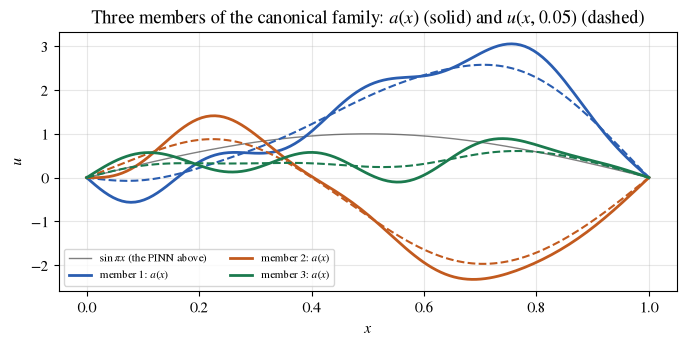

relative distance between a(x) and u(x, t_f) for each member (exact): [0.157 0.187 0.403]


In [11]:
C_FAMILY = heat1d.sample_family(3, 3)        # three members, c_k ~ N(0, 1/k^2)
T_FAMILY = heat1d.T_F                        # the operator modules' final time
x_fam = heat1d.X

def plot_heat_family():
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.plot(x_fam, heat1d.profile(C_FIRST, x_fam), color=fg(), lw=1, alpha=0.5,
            label='$\\sin\\pi x$ (the PINN above)')
    for k, c in enumerate(C_FAMILY):
        ax.plot(x_fam, heat1d.profile(c, x_fam), color=f'C{k}', lw=2, label=f'member {k+1}: $a(x)$')
        ax.plot(x_fam, heat1d.exact(c, x_fam, T_FAMILY), '--', color=f'C{k}', lw=1.5)
    ax.set(xlabel='$x$', ylabel='$u$',
           title=f'Three members of the canonical family: $a(x)$ (solid) and $u(x,{T_FAMILY})$ (dashed)')
    ax.legend(fontsize=8, ncol=2, loc='lower left')
    plt.tight_layout()

save_dual(plot_heat_family, 'pinn_heat_family', FIG)
plt.show()
A_FAMILY = np.array([heat1d.profile(c, x_fam) for c in C_FAMILY])
U_FAMILY = np.array([heat1d.exact(c, x_fam, T_FAMILY) for c in C_FAMILY])
print('relative distance between a(x) and u(x, t_f) for each member (exact):',
      np.round(heat1d.relative_l2(U_FAMILY, A_FAMILY), 3))